
# MMA3001 — Faster R-CNN Four-Class Object Detection

## Aim
To train and evaluate Faster R-CNN ResNet50-FPN V2 for detecting
and localising pork rasher packaging defects, and compare its
performance with YOLOv8n and RetinaNet.

## Defect Classes
1. loose-meat
2. packaging-error
3. twisted-meat
4. unsealed

The wrinkle class was excluded due to insufficient independent
source images for reliable model validation.

## Objectives
1. Adapt a pretrained Faster R-CNN model to the four-class dataset.
2. Train and select the best checkpoint using validation mAP@50:95.
3. Evaluate overall and per-class detection performance.
4. Compare confusion matrices at different confidence thresholds.
5. Analyse micro-F1, macro-F1 and per-class recall.
6. Measure computational cost, including inference speed and memory.
7. Prepare results for the final three-model comparison.

## Methodology
All models use identical dataset splits and comparable evaluation
procedures. Hyperparameters and model-specific processing
requirements are documented.

The held-out test dataset is reserved for the final comparison
after model selection is completed.



## 1. Environment Setup

The required PyTorch, Torchvision and evaluation libraries are
initialised. Google Drive is mounted to access the four-class
dataset and save model checkpoints.

A fixed random seed is used to improve reproducibility, while
GPU acceleration is enabled where available.


In [1]:

%pip install -q torchmetrics pycocotools pandas matplotlib

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from PIL import Image
import random
import time
import shutil
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.ops import box_iou

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2,
    FasterRCNN_ResNet50_FPN_V2_Weights
)
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)

from torchmetrics.detection.mean_ap import MeanAveragePrecision

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 54.4 MB/s eta 0:00:00
Mounted at /content/drive
Device: cuda
GPU: Tesla T4



## 2. Dataset Configuration

The same four-class dataset used for YOLOv8n and RetinaNet is
selected to ensure consistent training and validation splits.

The original YOLO annotations use zero-based class IDs, while
Torchvision Faster R-CNN requires class IDs starting from 1,
with 0 representing background.

Results and checkpoints are stored separately from the other
models to prevent overwriting previous experiments.


In [2]:

dataset_root = Path(
    "/content/drive/MyDrive/MMA3001_Project/"
    "dataset/pork_rasher_v4_4class"
)

run_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/"
    "model_runs/faster_rcnn_resnet50_4class"
)

run_dir.mkdir(parents=True, exist_ok=True)

best_model_path = run_dir / "best.pt"

CLASS_NAMES = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed"
]

NUM_CLASSES = len(CLASS_NAMES)
NUM_MODEL_CLASSES = NUM_CLASSES + 1

assert dataset_root.exists(), (
    f"Dataset not found: {dataset_root}"
)

for split in ["train", "valid", "test"]:
    for subfolder in ["images", "labels"]:
        path = dataset_root / split / subfolder
        assert path.exists(), f"Missing: {path}"

print("Dataset:", dataset_root)
print("Results:", run_dir)
print("Defect classes:", CLASS_NAMES)


Dataset: /content/drive/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class
Results: /content/drive/MyDrive/MMA3001_Project/model_runs/faster_rcnn_resnet50_4class
Defect classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed']



## 3. Dataset Conversion and Data Loading

The dataset annotations are converted from normalised YOLO
coordinates (x_center, y_center, width, height) to absolute
bounding-box coordinates (x_min, y_min, x_max, y_max).

The dataset class also shifts labels from 0–3 to 1–4 to match
Torchvision's background-class convention.

Images without defect annotations are retained as background
examples. The dataset is copied to local Colab storage to reduce
repeated Google Drive loading overhead.


In [3]:

class PorkRasherDataset(Dataset):
    """
    Four-class pork rasher object detection dataset.

    Converts YOLO normalised boxes to absolute xyxy boxes.
    Class labels are shifted from 0-3 to 1-4.

    Supports empty annotation files for background images.
    """

    def __init__(self, root, split):
        self.root = Path(root)
        self.split = split

        self.images_dir = self.root / split / "images"
        self.labels_dir = self.root / split / "labels"

        self.image_paths = sorted([
            p for p in self.images_dir.iterdir()
            if p.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".webp"
            }
        ])

        assert self.image_paths, (
            f"No images found in {self.images_dir}"
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]

        image = Image.open(image_path).convert("RGB")
        width, height = image.size

        label_path = (
            self.labels_dir / f"{image_path.stem}.txt"
        )

        boxes = []
        labels = []

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                if not line.strip():
                    continue

                values = list(map(float, line.split()))

                if len(values) != 5:
                    raise ValueError(
                        f"Invalid annotation: {label_path}"
                    )

                class_id = int(values[0])
                xc, yc, bw, bh = values[1:5]

                if not 0 <= class_id < NUM_CLASSES:
                    raise ValueError(
                        f"Invalid class ID in {label_path}"
                    )

                x1 = (xc - bw / 2) * width
                y1 = (yc - bh / 2) * height
                x2 = (xc + bw / 2) * width
                y2 = (yc + bh / 2) * height

                x1 = max(0, min(x1, width))
                y1 = max(0, min(y1, height))
                x2 = max(0, min(x2, width))
                y2 = max(0, min(y2, height))

                if x2 <= x1 or y2 <= y1:
                    raise ValueError(
                        f"Invalid box in {label_path}"
                    )

                boxes.append([x1, y1, x2, y2])
                labels.append(class_id + 1)

        boxes = torch.tensor(
            boxes, dtype=torch.float32
        ).reshape(-1, 4)

        labels = torch.tensor(
            labels, dtype=torch.int64
        )

        area = (
            (boxes[:, 2] - boxes[:, 0]) *
            (boxes[:, 3] - boxes[:, 1])
        )

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor(idx),
            "area": area,
            "iscrowd": torch.zeros(
                len(labels), dtype=torch.int64
            )
        }

        return TF.to_tensor(image), target


def collate_fn(batch):
    """
    Keep each image's target dictionary separate because
    images may contain different numbers of objects.
    """
    return tuple(zip(*batch))


# Faster data access during Colab training
local_dataset_root = Path(
    "/content/pork_rasher_v4_4class"
)

if not local_dataset_root.exists():
    print("Copying dataset to local Colab storage...")
    shutil.copytree(
        dataset_root,
        local_dataset_root
    )

active_root = local_dataset_root

train_dataset = PorkRasherDataset(active_root, "train")
valid_dataset = PorkRasherDataset(active_root, "valid")
test_dataset = PorkRasherDataset(active_root, "test")

print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    collate_fn=collate_fn
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    collate_fn=collate_fn
)


Copying dataset to local Colab storage...
Training images: 3138
Validation images: 120
Test images: 80



## 4. Annotation Verification

Sample images and their converted bounding boxes are visualised
before training.

This verifies that the coordinate conversion and class-label
mapping are correct, preventing annotation errors from affecting
the model comparison.


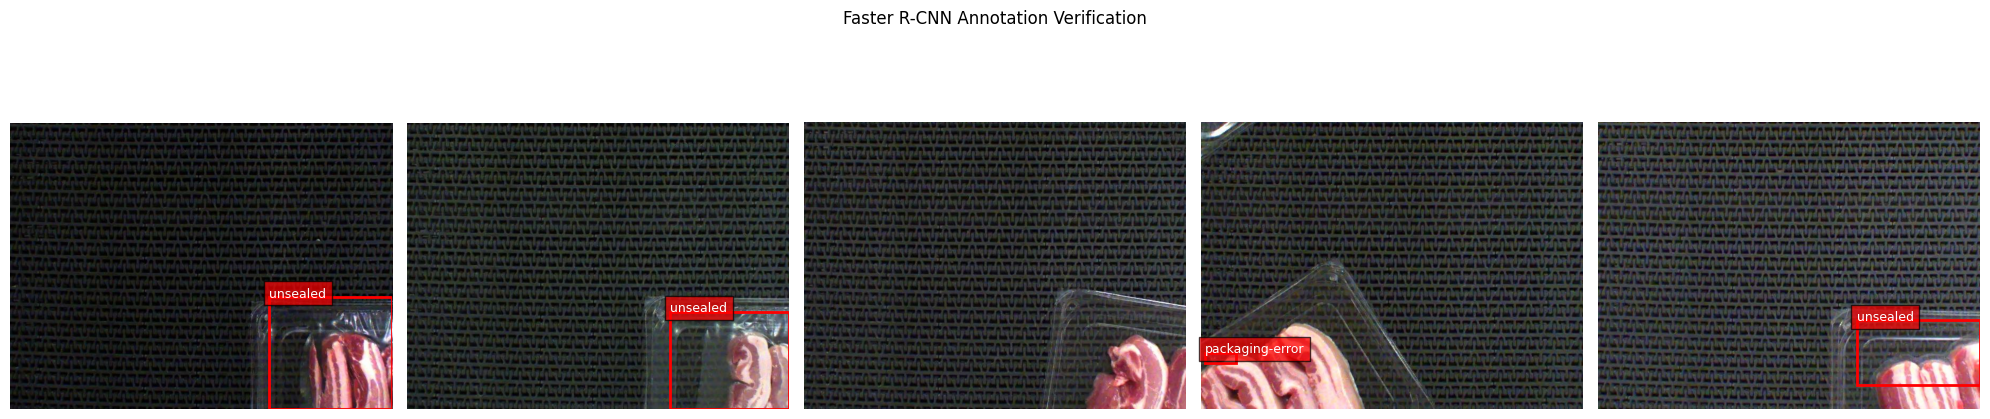

In [4]:

sample_indices = random.sample(
    range(len(train_dataset)),
    min(5, len(train_dataset))
)

fig, axes = plt.subplots(
    1,
    len(sample_indices),
    figsize=(20, 5)
)

axes = np.atleast_1d(axes)

for ax, idx in zip(axes, sample_indices):

    image, target = train_dataset[idx]

    ax.imshow(
        image.permute(1, 2, 0).numpy()
    )

    for box, label in zip(
        target["boxes"],
        target["labels"]
    ):
        x1, y1, x2, y2 = box.tolist()
        name = CLASS_NAMES[int(label) - 1]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        ax.add_patch(rect)

        ax.text(
            x1, y1,
            name,
            color="white",
            fontsize=9,
            bbox={
                "facecolor": "red",
                "alpha": 0.7
            }
        )

    ax.axis("off")

plt.suptitle(
    "Faster R-CNN Annotation Verification"
)
plt.tight_layout()
plt.show()



## 5. Faster R-CNN Model Initialisation

Faster R-CNN ResNet50-FPN V2 is initialised using COCO-pretrained
weights. Its classification and box-regression predictor is replaced
to support four defect classes and one background class.

Unlike YOLOv8n and RetinaNet, Faster R-CNN uses two detection stages:

1. A Region Proposal Network (RPN) generates candidate object regions.
2. An RoI detection head classifies the proposals and refines their
   bounding boxes.

This architecture provides a different approach to object detection,
allowing the effect of two-stage processing on accuracy and
computational cost to be investigated.

A forward-pass test is performed before training.


In [5]:

# Load COCO-pretrained Faster R-CNN ResNet50-FPN V2
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT

faster_rcnn = fasterrcnn_resnet50_fpn_v2(
    weights=weights,
    min_size=640,
    max_size=640
)

# Replace classification and box-regression predictor
in_features = (
    faster_rcnn.roi_heads.box_predictor
    .cls_score.in_features
)

faster_rcnn.roi_heads.box_predictor = (
    FastRCNNPredictor(
        in_channels=in_features,
        num_classes=NUM_MODEL_CLASSES
    )
)

# Preserve a sufficiently low model score threshold
# for subsequent validation confidence sweeps
faster_rcnn.roi_heads.score_thresh = 0.001

# NMS and maximum detections per image
faster_rcnn.roi_heads.nms_thresh = 0.50
faster_rcnn.roi_heads.detections_per_img = 100

faster_rcnn = faster_rcnn.to(device)

parameter_count = sum(
    p.numel() for p in faster_rcnn.parameters()
)

trainable_count = sum(
    p.numel()
    for p in faster_rcnn.parameters()
    if p.requires_grad
)

print("Architecture: Faster R-CNN ResNet50-FPN V2")
print("Pretrained weights: COCO")
print("Classes including background:", NUM_MODEL_CLASSES)
print("Parameters:", parameter_count)
print("Trainable parameters:", trainable_count)


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 181MB/s]


Architecture: Faster R-CNN ResNet50-FPN V2
Pretrained weights: COCO
Classes including background: 5
Parameters: 43271528
Trainable parameters: 43046184


In [6]:

images, targets = next(iter(train_loader))

images = [
    image.to(device)
    for image in images
]

targets = [
    {
        key: value.to(device)
        for key, value in target.items()
    }
    for target in targets
]

# Training mode returns loss components
faster_rcnn.train()

with torch.no_grad():
    loss_dict = faster_rcnn(images, targets)

print("Faster R-CNN Loss Components")

for name, loss in loss_dict.items():
    print(f"{name}: {loss.item():.4f}")

print(
    "Total:",
    sum(loss_dict.values()).item()
)

faster_rcnn.eval()


Faster R-CNN Loss Components
loss_classifier: 1.8824
loss_box_reg: 0.0204
loss_objectness: 0.1160
loss_rpn_box_reg: 0.0152
Total: 2.0341286659240723


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(640,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        


## 6. Model Training and Validation

The pretrained Faster R-CNN model is fine-tuned for 15 epochs using
SGD with momentum and weight decay. Mixed-precision training is
enabled on CUDA to reduce GPU memory usage and training time.

Validation mAP@50 and mAP@50:95 are calculated after every epoch.

The checkpoint with the highest validation mAP@50:95 is saved.
This prevents the experiment from automatically selecting the
final epoch when earlier epochs may generalise better.

Training time and validation performance are recorded to support
comparison with YOLOv8n and RetinaNet.


In [7]:

@torch.no_grad()
def evaluate_model(model, data_loader):
    """
    Calculate object detection mAP on a supplied DataLoader.

    Metrics:
        mAP@50
        mAP@50:95
        Per-class AP

    Uses TorchMetrics COCO-style bounding-box evaluation.
    """

    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=True
    )

    for images, targets in data_loader:

        images_gpu = [
            image.to(device)
            for image in images
        ]

        predictions = model(images_gpu)

        predictions_cpu = [
            {
                "boxes": p["boxes"].detach().cpu(),
                "scores": p["scores"].detach().cpu(),
                "labels": p["labels"].detach().cpu()
            }
            for p in predictions
        ]

        targets_cpu = [
            {
                "boxes": t["boxes"].cpu(),
                "labels": t["labels"].cpu()
            }
            for t in targets
        ]

        metric.update(
            predictions_cpu,
            targets_cpu
        )

    return metric.compute()


In [8]:

NUM_EPOCHS = 15
LEARNING_RATE = 0.005

optimizer = torch.optim.SGD(
    faster_rcnn.parameters(),
    lr=LEARNING_RATE,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

amp_enabled = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=amp_enabled
)

best_map = -1.0
history = []

training_start = time.perf_counter()

for epoch in range(1, NUM_EPOCHS + 1):

    faster_rcnn.train()

    epoch_loss = 0.0
    epoch_start = time.perf_counter()

    for batch_idx, (images, targets) in enumerate(
        train_loader,
        start=1
    ):

        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]

        targets = [
            {
                key: value.to(
                    device,
                    non_blocking=True
                )
                for key, value in target.items()
            }
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        # GPU mixed-precision forward pass
        with torch.autocast(
            device_type=device.type,
            enabled=amp_enabled
        ):

            loss_dict = faster_rcnn(
                images,
                targets
            )

            loss = sum(loss_dict.values())

        # Backpropagation
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()

        if batch_idx % 50 == 0:
            print(
                f"Epoch {epoch}/{NUM_EPOCHS} "
                f"Batch {batch_idx}/{len(train_loader)} "
                f"Loss: {loss.item():.4f}"
            )

    # Average training loss
    avg_loss = epoch_loss / len(train_loader)

    # Validation after each epoch
    validation_metrics = evaluate_model(
        faster_rcnn,
        valid_loader
    )

    val_map50 = float(
        validation_metrics["map_50"]
    )

    val_map = float(
        validation_metrics["map"]
    )

    epoch_seconds = (
        time.perf_counter() - epoch_start
    )

    history.append({
        "Epoch": epoch,
        "Train_Loss": avg_loss,
        "Val_mAP50": val_map50,
        "Val_mAP50_95": val_map,
        "Epoch_Seconds": epoch_seconds
    })

    pd.DataFrame(history).to_csv(
        run_dir / "training_history.csv",
        index=False
    )

    # Save best checkpoint based on validation mAP
    if val_map > best_map:

        best_map = val_map

        torch.save({
            "epoch": epoch,
            "model_state": faster_rcnn.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "val_map": val_map
        }, best_model_path)

        print("New best checkpoint saved!")

    scheduler.step()

    print(
        f"\nEpoch {epoch}/{NUM_EPOCHS}"
        f"\nTraining loss: {avg_loss:.4f}"
        f"\nValidation mAP@50: {val_map50:.4f}"
        f"\nValidation mAP@50:95: {val_map:.4f}"
        f"\nEpoch time: {epoch_seconds:.1f} s"
        f"\nBest mAP@50:95: {best_map:.4f}\n"
    )

training_seconds = (
    time.perf_counter() - training_start
)

print("Training completed!")
print("Total training time:", training_seconds)
print("Best validation mAP@50:95:", best_map)
print("Checkpoint:", best_model_path)


Epoch 1/15 Batch 50/785 Loss: 0.3234
Epoch 1/15 Batch 100/785 Loss: 0.3739
Epoch 1/15 Batch 150/785 Loss: 0.1653
Epoch 1/15 Batch 200/785 Loss: 0.1232
Epoch 1/15 Batch 250/785 Loss: 0.0402
Epoch 1/15 Batch 300/785 Loss: 0.0605
Epoch 1/15 Batch 350/785 Loss: 0.1493
Epoch 1/15 Batch 400/785 Loss: 0.1061
Epoch 1/15 Batch 450/785 Loss: 0.1640
Epoch 1/15 Batch 500/785 Loss: 0.1441
Epoch 1/15 Batch 550/785 Loss: 0.2089
Epoch 1/15 Batch 600/785 Loss: 0.2066
Epoch 1/15 Batch 650/785 Loss: 0.1491
Epoch 1/15 Batch 700/785 Loss: 0.0854
Epoch 1/15 Batch 750/785 Loss: 0.1010
New best checkpoint saved!

Epoch 1/15
Training loss: 0.1549
Validation mAP@50: 0.3299
Validation mAP@50:95: 0.1883
Epoch time: 265.4 s
Best mAP@50:95: 0.1883

Epoch 2/15 Batch 50/785 Loss: 0.1421
Epoch 2/15 Batch 100/785 Loss: 0.1175
Epoch 2/15 Batch 150/785 Loss: 0.0705
Epoch 2/15 Batch 200/785 Loss: 0.0750
Epoch 2/15 Batch 250/785 Loss: 0.1238
Epoch 2/15 Batch 300/785 Loss: 0.1136
Epoch 2/15 Batch 350/785 Loss: 0.0640
Epoch 


## 7. Training Performance Analysis

Training loss and validation mAP are plotted against the number
of epochs to examine model convergence.

A reduction in training loss accompanied by stagnant or decreasing
validation mAP may indicate overfitting.

The checkpoint achieving the highest validation mAP@50:95 is
reloaded before further evaluation, ensuring that subsequent
results correspond to the selected model.


,Epoch,Train_Loss,Val_mAP50,Val_mAP50_95,Epoch_Seconds
0,1,0.1549,0.3299,0.1883,265.3867
1,2,0.0956,0.4093,0.1983,287.1151
2,3,0.0686,0.5662,0.3222,291.0855
3,4,0.0496,0.4661,0.3036,292.0423
4,5,0.0371,0.5370,0.3130,290.6363
5,6,0.0245,0.5280,0.3149,291.6250
6,7,0.0183,0.5250,0.3095,290.7815
7,8,0.0158,0.5011,0.2810,298.7953
8,9,0.0142,0.5270,0.2788,292.6684
9,10,0.0131,0.5342,0.2913,291.1179


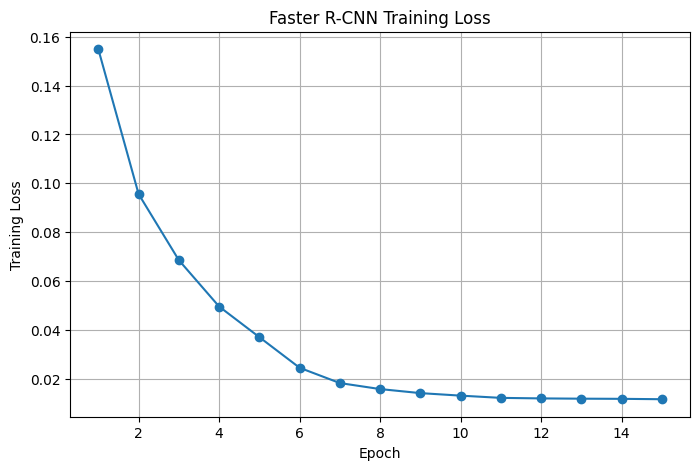

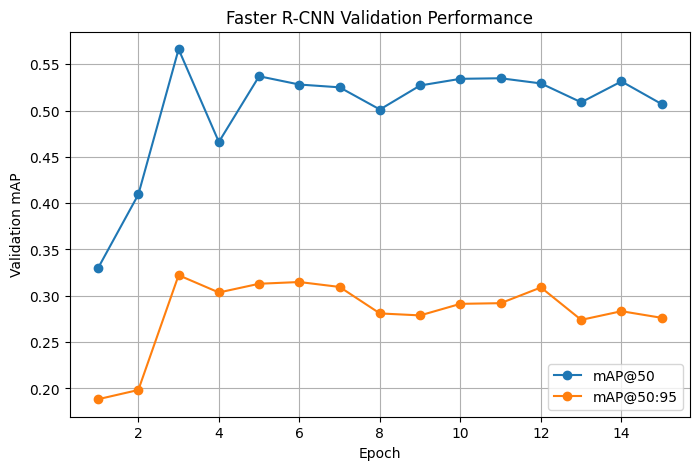

Best epoch: 3
Best validation mAP@50:95: 0.32222098112106323


In [9]:

history_df = pd.read_csv(
    run_dir / "training_history.csv"
)

display(history_df.round(4))

# Plot training loss
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train_Loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Faster R-CNN Training Loss")
plt.grid(True)

plt.savefig(
    run_dir / "training_loss.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


# Plot validation mAP
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Val_mAP50"],
    marker="o",
    label="mAP@50"
)

plt.plot(
    history_df["Epoch"],
    history_df["Val_mAP50_95"],
    marker="o",
    label="mAP@50:95"
)

plt.xlabel("Epoch")
plt.ylabel("Validation mAP")
plt.title("Faster R-CNN Validation Performance")
plt.legend()
plt.grid(True)

plt.savefig(
    run_dir / "validation_map.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


# Reload best model
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

faster_rcnn.load_state_dict(
    checkpoint["model_state"]
)

faster_rcnn.eval()

print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation mAP@50:95:",
    checkpoint["val_map"]
)



## 8. Overall and Per-Class Detection Performance

The selected model is evaluated on the validation dataset using
COCO-style mAP@50 and mAP@50:95.

Per-class average precision is calculated for loose-meat,
packaging-error, twisted-meat and unsealed defects.

These measurements are used to identify strengths and weaknesses
of the two-stage detector, particularly for minority defect classes.

The final model comparison will evaluate all three detectors
using a common evaluation implementation.


In [10]:

validation_results = evaluate_model(
    faster_rcnn,
    valid_loader
)

print("FOUR-CLASS FASTER R-CNN VALIDATION")
print("--------------------------------")

print(
    "mAP@50:",
    round(float(validation_results["map_50"]), 4)
)

print(
    "mAP@50:95:",
    round(float(validation_results["map"]), 4)
)

per_class_rows = []

for class_id, ap in zip(
    validation_results["classes"],
    validation_results["map_per_class"]
):

    class_index = int(class_id) - 1

    per_class_rows.append({
        "Class": CLASS_NAMES[class_index],
        "mAP@50:95": float(ap)
    })

per_class_df = pd.DataFrame(
    per_class_rows
)

print("\nPER-CLASS mAP@50:95")
display(per_class_df.round(4))

per_class_df.to_csv(
    run_dir / "per_class_ap.csv",
    index=False
)


FOUR-CLASS FASTER R-CNN VALIDATION
--------------------------------
mAP@50: 0.5662
mAP@50:95: 0.3222

PER-CLASS mAP@50:95


,Class,mAP@50:95
0,loose-meat,0.4663
1,packaging-error,0.0458
2,twisted-meat,0.2020
3,unsealed,0.5748



## 9. Confidence Threshold Evaluation

Predictions are collected from the validation dataset and
evaluated at confidence thresholds of 0.10, 0.25, 0.50,
0.70 and 0.849.

The same custom matching procedure used for YOLOv8n and
RetinaNet is applied, with an IoU threshold of 0.50.

Each prediction is matched to at most one ground-truth object.
Correct detections, incorrect classifications, false positives
and missed detections are recorded.

Overall precision, recall, micro-F1 and macro-F1 are calculated
to investigate the influence of confidence thresholds.


In [11]:

@torch.no_grad()
def collect_predictions(model, data_loader):
    """
    Run inference once and store predictions for all
    validation images.

    The stored outputs are reused during threshold
    analysis without rerunning the detector.
    """

    model.eval()

    predictions_all = []
    targets_all = []

    for images, targets in data_loader:

        images_gpu = [
            image.to(device)
            for image in images
        ]

        outputs = model(images_gpu)

        for output, target in zip(outputs, targets):

            predictions_all.append({
                "boxes": output["boxes"].detach().cpu(),
                "scores": output["scores"].detach().cpu(),
                "labels": output["labels"].detach().cpu()
            })

            targets_all.append({
                "boxes": target["boxes"].cpu(),
                "labels": target["labels"].cpu()
            })

    return predictions_all, targets_all


predictions_all, targets_all = collect_predictions(
    faster_rcnn,
    valid_loader
)

assert len(predictions_all) == len(targets_all)

print("Prediction images:", len(predictions_all))
print("Ground-truth images:", len(targets_all))

print(
    "Internal score threshold:",
    faster_rcnn.roi_heads.score_thresh
)
print(
    "NMS threshold:",
    faster_rcnn.roi_heads.nms_thresh
)
print(
    "Maximum detections:",
    faster_rcnn.roi_heads.detections_per_img
)


Prediction images: 120
Ground-truth images: 120
Internal score threshold: 0.001
NMS threshold: 0.5
Maximum detections: 100


In [12]:

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

N = NUM_CLASSES
BACKGROUND = N

MATRIX_LABELS = CLASS_NAMES + ["background"]


def make_confusion_matrix(threshold):
    """
    Rows: predicted classes
    Columns: actual classes

    Matches predictions in descending confidence order
    against unused ground-truth boxes.

    IoU >= 0.50 is required for a match.
    """

    cm = np.zeros((N + 1, N + 1), dtype=int)

    for prediction, target in zip(
        predictions_all,
        targets_all
    ):

        keep = prediction["scores"] >= threshold

        pred_boxes = prediction["boxes"][keep]
        pred_scores = prediction["scores"][keep]
        pred_labels = prediction["labels"][keep]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        order = torch.argsort(
            pred_scores, descending=True
        )

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for pred_box, pred_label in zip(
            pred_boxes, pred_labels
        ):

            pred_index = int(pred_label) - 1

            if not (0 <= pred_index < N):
                continue

            if len(gt_boxes) == 0:
                cm[pred_index, BACKGROUND] += 1
                continue

            ious = box_iou(
                pred_box.unsqueeze(0),
                gt_boxes
            )[0]

            for idx in matched_gt:
                ious[idx] = -1

            best_iou, best_idx = ious.max(0)
            best_idx = int(best_idx)

            if best_iou >= IOU_THRESHOLD:

                true_index = (
                    int(gt_labels[best_idx]) - 1
                )

                cm[pred_index, true_index] += 1
                matched_gt.add(best_idx)

            else:
                cm[pred_index, BACKGROUND] += 1

        # Count ground truths that were not detected
        for idx, label in enumerate(gt_labels):
            if idx not in matched_gt:
                cm[BACKGROUND, int(label) - 1] += 1

    return cm


def calculate_metrics(cm, threshold):
    """
    Calculate detection-level metrics.

    Wrong-class matches count as both:
      - a false positive for the predicted class
      - a false negative for the actual class
    """

    tp = int(np.trace(cm[:N, :N]))
    fp = int(cm[:N, :].sum() - tp)
    fn = int(cm[:, :N].sum() - tp)

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    micro_f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    result = {
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "Micro-F1": micro_f1
    }

    class_f1_values = []
    class_recall_values = []

    for i, name in enumerate(CLASS_NAMES):

        class_tp = int(cm[i, i])
        class_fp = int(cm[i, :].sum() - class_tp)
        class_fn = int(cm[:, i].sum() - class_tp)

        class_precision = (
            class_tp / (class_tp + class_fp)
            if class_tp + class_fp else 0
        )

        class_recall = (
            class_tp / (class_tp + class_fn)
            if class_tp + class_fn else 0
        )

        class_f1 = (
            2 * class_precision * class_recall /
            (class_precision + class_recall)
            if class_precision + class_recall else 0
        )

        class_f1_values.append(class_f1)
        class_recall_values.append(class_recall)

        result[f"{name}_TP"] = class_tp
        result[f"{name}_Recall"] = class_recall
        result[f"{name}_F1"] = class_f1

    result["Macro-F1"] = float(np.mean(class_f1_values))
    result["Macro-Recall"] = float(
        np.mean(class_recall_values)
    )

    return result


matrices = [
    make_confusion_matrix(t)
    for t in THRESHOLDS
]

summary_df = pd.DataFrame([
    calculate_metrics(cm, threshold)
    for cm, threshold in zip(matrices, THRESHOLDS)
])

display(
    summary_df[
        [
            "Threshold", "TP", "FP", "FN",
            "Precision", "Recall",
            "Micro-F1", "Macro-F1"
        ]
    ].round(4)
)

summary_df.to_csv(
    run_dir / "threshold_comparison.csv",
    index=False
)


,Threshold,TP,FP,FN,Precision,Recall,Micro-F1,Macro-F1
0,0.100,89,82,32,0.5205,0.7355,0.6096,0.4375
1,0.250,84,52,37,0.6176,0.6942,0.6537,0.4931
2,0.500,80,34,41,0.7018,0.6612,0.6809,0.5962
3,0.700,75,22,46,0.7732,0.6198,0.6881,0.3910
4,0.849,72,16,49,0.8182,0.5950,0.6890,0.2531



## 10. Confusion Matrix Analysis

Raw and normalised confusion matrices are generated at five
confidence thresholds.

The raw matrices show the actual number of detections,
misclassifications and background errors.

The normalised matrices divide each column by the total number
of examples in that column, allowing detection proportions
to be compared despite differences in class frequency.

The effect of confidence thresholds on false positives
and false negatives is examined.


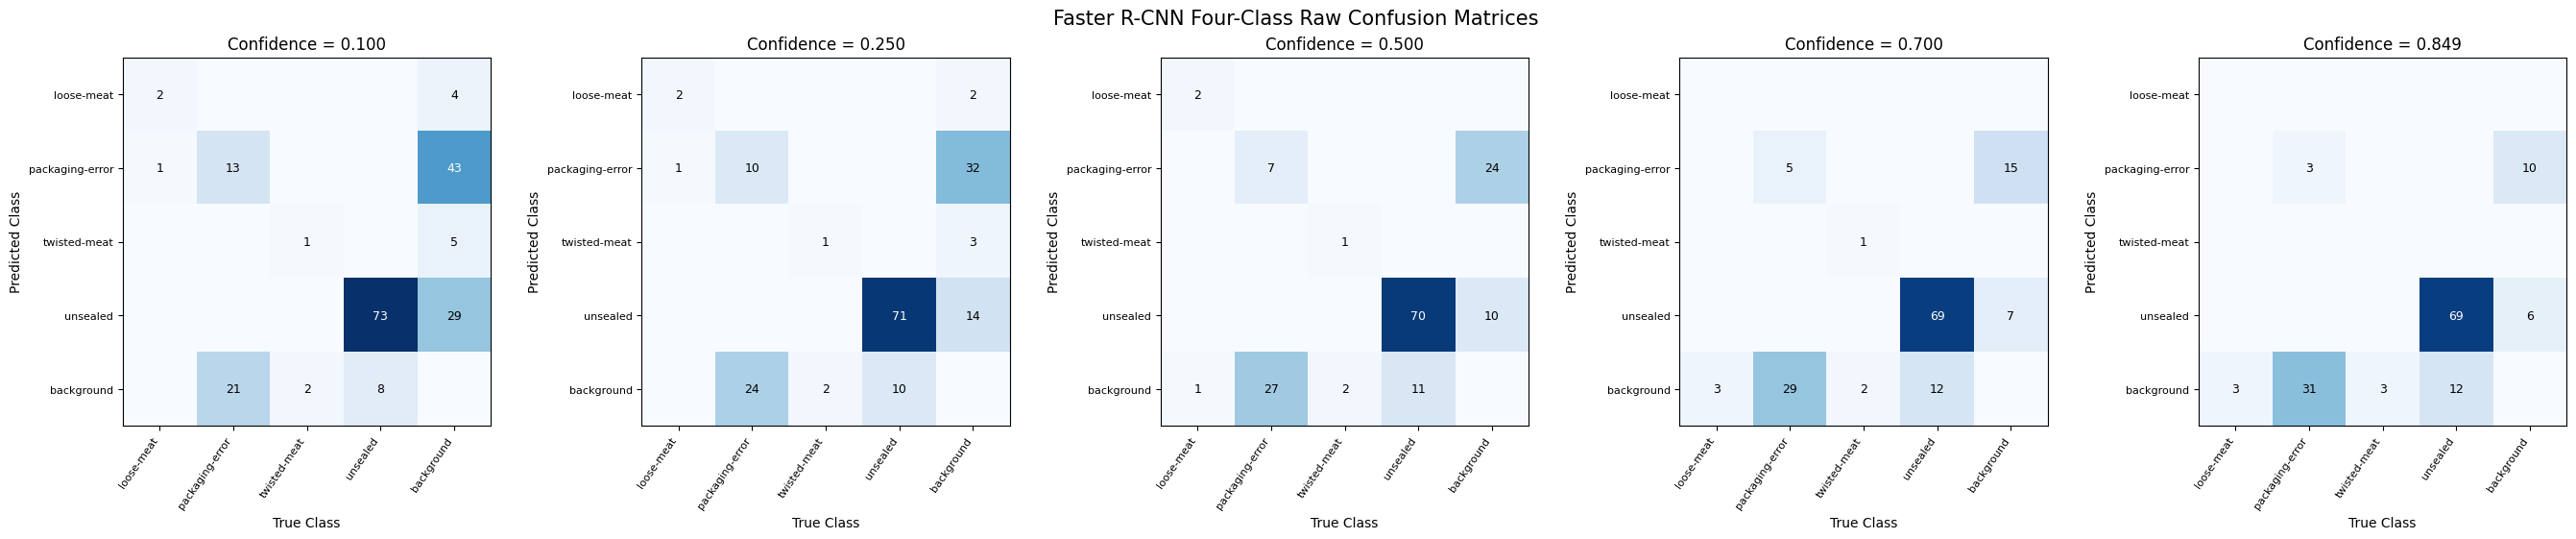

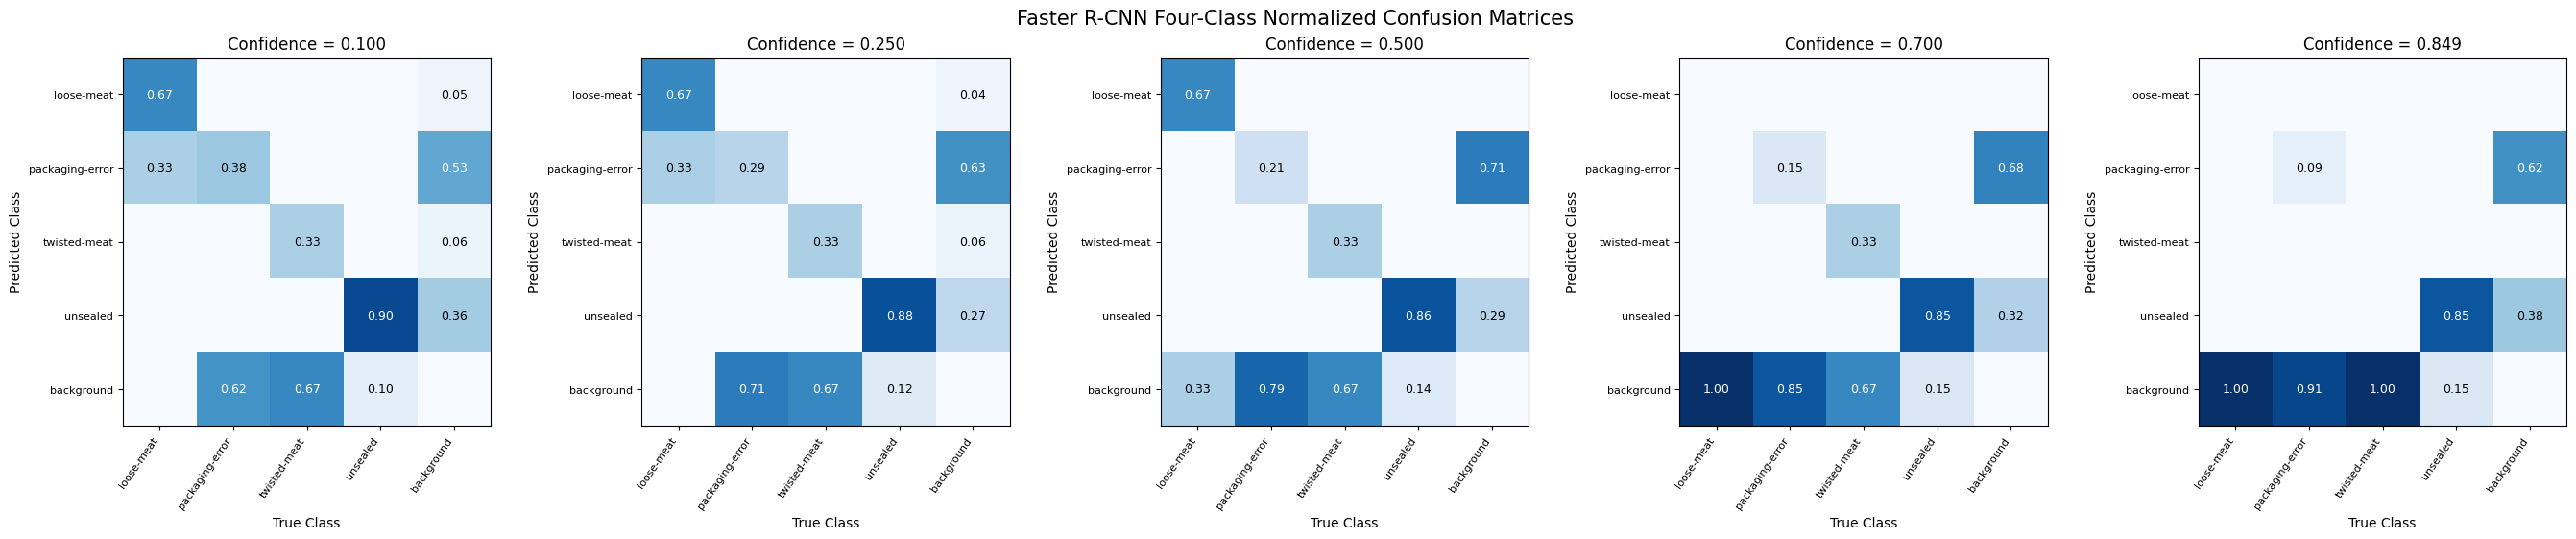

In [13]:

def plot_confusion_matrices(
    matrices,
    thresholds,
    normalized=False
):

    fig, axes = plt.subplots(
        1,
        len(thresholds),
        figsize=(27, 5.5),
        constrained_layout=True
    )

    max_value = (
        1.0 if normalized
        else max(cm.max() for cm in matrices)
    )

    for ax, threshold, cm in zip(
        axes, thresholds, matrices
    ):

        if normalized:
            column_sums = cm.sum(
                axis=0, keepdims=True
            )

            data = np.divide(
                cm.astype(float),
                column_sums,
                out=np.zeros_like(cm, dtype=float),
                where=column_sums != 0
            )
        else:
            data = cm

        ax.imshow(
            data,
            cmap="Blues",
            vmin=0,
            vmax=max_value
        )

        ax.set_title(
            f"Confidence = {threshold:.3f}"
        )

        ax.set_xticks(range(N + 1))
        ax.set_yticks(range(N + 1))

        ax.set_xticklabels(
            MATRIX_LABELS,
            rotation=55,
            ha="right",
            fontsize=8
        )

        ax.set_yticklabels(
            MATRIX_LABELS,
            fontsize=8
        )

        ax.set_xlabel("True Class")
        ax.set_ylabel("Predicted Class")

        for row in range(N + 1):
            for col in range(N + 1):

                value = data[row, col]

                if value > 0:

                    label = (
                        f"{value:.2f}"
                        if normalized
                        else str(value)
                    )

                    ax.text(
                        col, row, label,
                        ha="center",
                        va="center",
                        fontsize=9,
                        color=(
                            "white" if value > max_value / 2
                            else "black"
                        )
                    )

    kind = "normalized" if normalized else "raw"

    fig.suptitle(
        f"Faster R-CNN Four-Class {kind.title()} "
        "Confusion Matrices",
        fontsize=15
    )

    fig.savefig(
        run_dir / f"confusion_matrices_{kind}.png",
        dpi=160,
        bbox_inches="tight"
    )

    plt.show()


plot_confusion_matrices(
    matrices, THRESHOLDS, normalized=False
)

plot_confusion_matrices(
    matrices, THRESHOLDS, normalized=True
)



## 11. Confidence Threshold Sensitivity Analysis

A finer confidence-threshold sweep is performed between
0.10 and 0.50 using increments of 0.025.

For each threshold, precision, recall, micro-F1, macro-F1
and macro-recall are calculated.

The best micro-F1 and macro-F1 operating points are identified
using validation data only.

Per-class recall is also examined to determine whether a high
overall score hides poor performance on minority defect classes.


FINE THRESHOLD COMPARISON


,Threshold,Precision,Recall,Micro-F1,Macro-F1,Macro-Recall
0,0.100,0.5205,0.7355,0.6096,0.4375,0.5709
1,0.125,0.5399,0.7273,0.6197,0.4526,0.5635
2,0.150,0.5714,0.7273,0.6400,0.4625,0.5635
3,0.175,0.5789,0.7273,0.6447,0.4642,0.5635
4,0.200,0.5986,0.7273,0.6567,0.4924,0.5635
5,0.225,0.6187,0.7107,0.6615,0.4914,0.5531
6,0.250,0.6176,0.6942,0.6537,0.4931,0.5427
7,0.275,0.6241,0.6860,0.6535,0.5159,0.5353
8,0.300,0.6288,0.6860,0.6561,0.5172,0.5353
9,0.325,0.6434,0.6860,0.6640,0.5201,0.5353



BEST MICRO-F1 THRESHOLD
Threshold: 0.500
Micro-F1: 0.6809
Precision: 0.7018
Recall: 0.6612

BEST MACRO-F1 THRESHOLD
Threshold: 0.500
Macro-F1: 0.5962


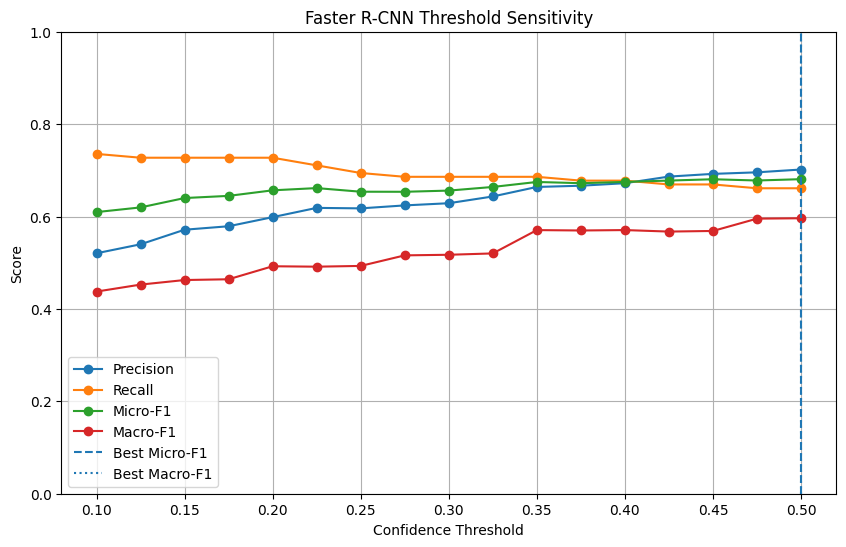


PER-CLASS RECALL


,Threshold,loose-meat,packaging-error,twisted-meat,unsealed
0,0.100,0.6667,0.3824,0.3333,0.9012
1,0.125,0.6667,0.3529,0.3333,0.9012
2,0.150,0.6667,0.3529,0.3333,0.9012
3,0.175,0.6667,0.3529,0.3333,0.9012
4,0.200,0.6667,0.3529,0.3333,0.9012
5,0.225,0.6667,0.3235,0.3333,0.8889
6,0.250,0.6667,0.2941,0.3333,0.8765
7,0.275,0.6667,0.2647,0.3333,0.8765
8,0.300,0.6667,0.2647,0.3333,0.8765
9,0.325,0.6667,0.2647,0.3333,0.8765


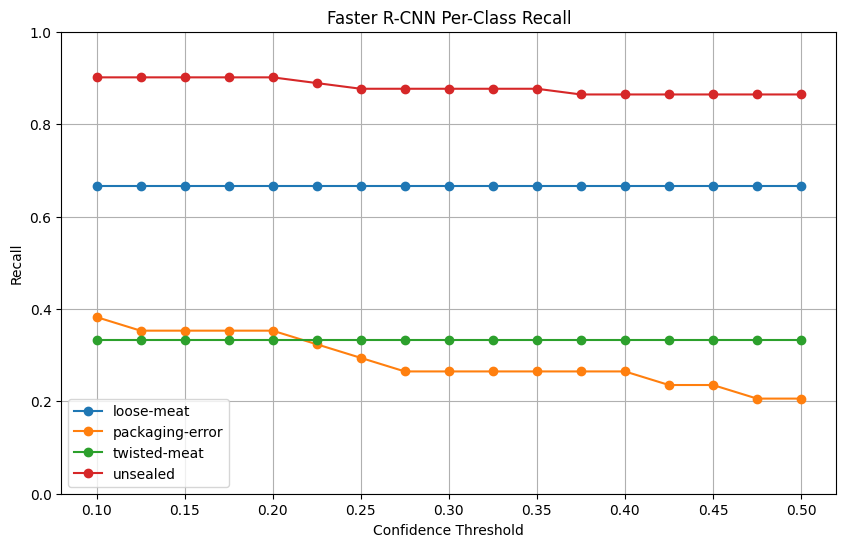


RECALL AT SELECTED THRESHOLDS


,Threshold,loose-meat,packaging-error,twisted-meat,unsealed
16,0.5,0.6667,0.2059,0.3333,0.8642


In [14]:

FINE_THRESHOLDS = np.round(
    np.arange(0.10, 0.5001, 0.025), 3
)

fine_df = pd.DataFrame([
    calculate_metrics(
        make_confusion_matrix(float(t)),
        float(t)
    )
    for t in FINE_THRESHOLDS
])

print("FINE THRESHOLD COMPARISON")

display(
    fine_df[
        [
            "Threshold",
            "Precision",
            "Recall",
            "Micro-F1",
            "Macro-F1",
            "Macro-Recall"
        ]
    ].round(4)
)

best_micro = fine_df.loc[
    fine_df["Micro-F1"].idxmax()
]

best_macro = fine_df.loc[
    fine_df["Macro-F1"].idxmax()
]

print("\nBEST MICRO-F1 THRESHOLD")
print(f"Threshold: {best_micro['Threshold']:.3f}")
print(f"Micro-F1: {best_micro['Micro-F1']:.4f}")
print(f"Precision: {best_micro['Precision']:.4f}")
print(f"Recall: {best_micro['Recall']:.4f}")

print("\nBEST MACRO-F1 THRESHOLD")
print(f"Threshold: {best_macro['Threshold']:.3f}")
print(f"Macro-F1: {best_macro['Macro-F1']:.4f}")


# Overall threshold curves
plt.figure(figsize=(10, 6))

for metric in [
    "Precision", "Recall", "Micro-F1", "Macro-F1"
]:
    plt.plot(
        fine_df["Threshold"],
        fine_df[metric],
        marker="o",
        label=metric
    )

plt.axvline(
    best_micro["Threshold"],
    linestyle="--",
    label="Best Micro-F1"
)

plt.axvline(
    best_macro["Threshold"],
    linestyle=":",
    label="Best Macro-F1"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title("Faster R-CNN Threshold Sensitivity")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.savefig(
    run_dir / "fine_threshold_sensitivity.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# Per-class recall
recall_df = fine_df[
    ["Threshold"] +
    [f"{name}_Recall" for name in CLASS_NAMES]
].copy()

recall_df.columns = ["Threshold"] + CLASS_NAMES

print("\nPER-CLASS RECALL")
display(recall_df.round(4))

plt.figure(figsize=(10, 6))

for name in CLASS_NAMES:
    plt.plot(
        recall_df["Threshold"],
        recall_df[name],
        marker="o",
        label=name
    )

plt.xlabel("Confidence Threshold")
plt.ylabel("Recall")
plt.title("Faster R-CNN Per-Class Recall")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.savefig(
    run_dir / "per_class_recall.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


# Save detailed results
fine_df.to_csv(
    run_dir / "fine_threshold_comparison.csv",
    index=False
)

selected_thresholds = sorted(set([
    float(best_micro["Threshold"]),
    float(best_macro["Threshold"])
]))

print("\nRECALL AT SELECTED THRESHOLDS")

display(
    recall_df[
        recall_df["Threshold"].isin(
            selected_thresholds
        )
    ].round(4)
)



## 12. Computational Performance Evaluation

The computational requirements of Faster R-CNN are evaluated
using parameter count, checkpoint file size, inference time,
frames per second (FPS), training duration and peak GPU memory.

Inference is benchmarked using repeated single-image forward
passes after GPU warm-up to reduce the influence of initialisation.

These results will be compared against YOLOv8n and RetinaNet
using the same hardware and measurement methodology.

The objective is to determine whether any improvement in
detection performance justifies the additional computational cost.


In [15]:

faster_rcnn.eval()

# Number of model parameters
parameter_count = sum(
    p.numel() for p in faster_rcnn.parameters()
)

# Saved checkpoint size
checkpoint_size_mb = (
    best_model_path.stat().st_size / (1024 ** 2)
)

# Sample validation image
sample_image, _ = valid_dataset[0]
sample_image = sample_image.to(device)

# GPU warm-up
with torch.no_grad():
    for _ in range(10):
        _ = faster_rcnn([sample_image])

if device.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

inference_times = []

with torch.no_grad():
    for _ in range(50):

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        _ = faster_rcnn([sample_image])

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        inference_times.append(elapsed * 1000)

median_inference_ms = float(
    np.median(inference_times)
)

fps = 1000 / median_inference_ms

if device.type == "cuda":
    peak_gpu_mb = (
        torch.cuda.max_memory_allocated() /
        (1024 ** 2)
    )
else:
    peak_gpu_mb = np.nan

# Recover training duration from saved epoch records,
# including when this cell is run after a runtime restart.
training_history = pd.read_csv(
    run_dir / "training_history.csv"
)

training_seconds = float(
    training_history["Epoch_Seconds"].sum()
)

compute_results = pd.DataFrame([{
    "Model": "Faster R-CNN ResNet50-FPN V2",
    "Parameters": parameter_count,
    "Checkpoint_MB": checkpoint_size_mb,
    "Inference_ms": median_inference_ms,
    "FPS": fps,
    "Peak_GPU_MB": peak_gpu_mb,
    "Training_seconds": training_seconds
}])

print("FASTER R-CNN COMPUTATIONAL PERFORMANCE")
display(compute_results.round(4))

compute_results.to_csv(
    run_dir / "computational_performance.csv",
    index=False
)


FASTER R-CNN COMPUTATIONAL PERFORMANCE


,Model,Parameters,Checkpoint_MB,Inference_ms,FPS,Peak_GPU_MB,Training_seconds
0,Faster R-CNN ResNet50-FPN V2,43271528,329.6558,132.3379,7.5564,1330.3657,4361.4358
